# What drives medical insurance costs? A statistical analysis

**Data:** 1,338 insured people in the US (age, sex, BMI, children, smoker, region, annual medical charges).

**Research questions**
1. Do smokers pay more — and by how much?
2. Do men pay more than women, or is that confounded?
3. Do costs differ by region?
4. How do age and BMI relate to cost, and does obesity matter *differently* for smokers?
5. Which model explains costs best, and do its assumptions hold?

Charges are strongly right-skewed, so every comparison uses both a parametric test and a **rank-based** test, and reports
an **effect size** with a confidence interval — a p-value alone says nothing about how *big* a difference is. α = 0.05.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import KFold
sys.path.insert(0, str(Path.cwd().parent))
from stats_utils import cohens_d, rank_biserial, cramers_v, eta_squared, pct_effect
sns.set_theme(style="whitegrid")
REPORTS = Path.cwd().parent / "reports"; REPORTS.mkdir(exist_ok=True)
raw = pd.read_csv("../data/insurance.csv")
d = raw.drop_duplicates().reset_index(drop=True)
d["obese"] = (d.bmi >= 30).astype(int)          # WHO definition of obesity
d["log_charges"] = np.log(d.charges)
R = {"n": len(d), "duplicates_removed": int(len(raw) - len(d))}
print(f"{len(d):,} people after removing {len(raw)-len(d)} exact duplicate row; no missing values")
d.describe().round(1)

1,337 people after removing 1 exact duplicate row; no missing values


,age,bmi,children,charges,obese,log_charges
count,1337.0,1337.0,1337.0,1337.0,1337.0,1337.0
mean,39.2,30.7,1.1,13279.1,0.5,9.1
std,14.0,6.1,1.2,12110.4,0.5,0.9
min,18.0,16.0,0.0,1121.9,0.0,7.0
25%,27.0,26.3,0.0,4746.3,0.0,8.5
50%,39.0,30.4,1.0,9386.2,1.0,9.1
75%,51.0,34.7,2.0,16657.7,1.0,9.7
max,64.0,53.1,5.0,63770.4,1.0,11.1


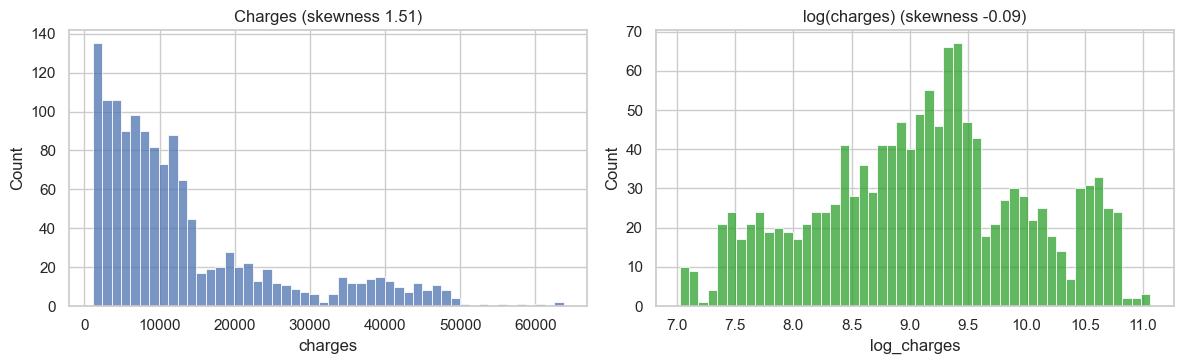

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(d.charges, bins=50, ax=ax[0]); ax[0].set(title=f"Charges (skewness {stats.skew(d.charges):.2f})")
sns.histplot(d.log_charges, bins=50, ax=ax[1], color="tab:green"); ax[1].set(title=f"log(charges) (skewness {stats.skew(d.log_charges):.2f})")
fig.tight_layout(); plt.show()

## RQ1 — Do smokers pay more?

In [3]:
s, n = d.charges[d.smoker == "yes"], d.charges[d.smoker == "no"]
t_ = stats.ttest_ind(s, n, equal_var=False); mw = stats.mannwhitneyu(s, n)
rng = np.random.default_rng(42)
boot = [np.median(rng.choice(s, s.size)) - np.median(rng.choice(n, n.size)) for _ in range(5000)]
lo, hi = np.percentile(boot, [2.5, 97.5])
R["smoker"] = {"mean_smoker": s.mean(), "mean_non": n.mean(), "median_smoker": s.median(), "median_non": n.median(),
               "welch_p": t_.pvalue, "mw_p": mw.pvalue, "cohens_d": cohens_d(n, s), "rank_biserial": rank_biserial(n, s),
               "median_diff_ci": [lo, hi], "n_smokers": int(s.size)}
print(f"Smokers (n={s.size}): mean ${s.mean():,.0f}, median ${s.median():,.0f}")
print(f"Non-smokers (n={n.size}): mean ${n.mean():,.0f}, median ${n.median():,.0f}")
print(f"Welch t-test p = {t_.pvalue:.1e}; Mann-Whitney p = {mw.pvalue:.1e}")
print(f"Cohen's d = {cohens_d(n, s):.2f}; rank-biserial = {rank_biserial(n, s):.2f}")
print(f"Median difference ${np.median(s)-np.median(n):,.0f}, bootstrap 95% CI [${lo:,.0f}, ${hi:,.0f}]")

Smokers (n=274): mean $32,050, median $34,456
Non-smokers (n=1063): mean $8,441, median $7,346
Welch t-test p = 6.3e-103; Mann-Whitney p = 5.7e-130
Cohen's d = 3.16; rank-biserial = 0.95
Median difference $27,111, bootstrap 95% CI [$22,183, $28,876]


Smokers pay about **four times** as much. Cohen's d above 3 is an enormous effect (0.8 is conventionally "large"), and the
rank-biserial correlation shows a randomly chosen smoker pays more than a randomly chosen non-smoker in nearly every pairing.

## RQ2 — Do men pay more? A lesson in confounding

In [4]:
m, f = d.charges[d.sex == "male"], d.charges[d.sex == "female"]
tt = stats.ttest_ind(m, f, equal_var=False); mwu = stats.mannwhitneyu(m, f)
ct = pd.crosstab(d.sex, d.smoker)
chi2, p_chi, _, _ = stats.chi2_contingency(ct, correction=False)
R["sex"] = {"mean_male": m.mean(), "mean_female": f.mean(), "welch_p": tt.pvalue, "mw_p": mwu.pvalue,
            "smoking_rate_male": float((d[d.sex=="male"].smoker=="yes").mean()),
            "smoking_rate_female": float((d[d.sex=="female"].smoker=="yes").mean()), "chi2_p": p_chi, "cramers_v": cramers_v(ct)}
print(f"Mean charges: men ${m.mean():,.0f}, women ${f.mean():,.0f} (Welch p = {tt.pvalue:.3f}, Mann-Whitney p = {mwu.pvalue:.3f})")
print(f"Smoking rate: men {R['sex']['smoking_rate_male']:.1%}, women {R['sex']['smoking_rate_female']:.1%} "
      f"(chi-square p = {p_chi:.3f}, Cramér's V = {cramers_v(ct):.2f})")

Mean charges: men $13,975, women $12,570 (Welch p = 0.034, Mann-Whitney p = 0.694)
Smoking rate: men 23.6%, women 17.4% (chi-square p = 0.005, Cramér's V = 0.08)


Men's *mean* charges are significantly higher (Welch p ≈ 0.03) but the rank-based test finds no difference (p ≈ 0.69) — the gap comes from a minority of very expensive men, and **men also smoke more**. Sex
could look important only because it is correlated with smoking — a *confounder*. The regression in RQ5 separates the two.

## RQ3 — Do costs differ by region?

In [5]:
groups = [g.values for _, g in d.groupby("region").log_charges]
kw = stats.kruskal(*[g.values for _, g in d.groupby("region").charges])
an = stats.f_oneway(*groups)
tukey = pairwise_tukeyhsd(d.log_charges, d.region)
R["region"] = {"kruskal_p": kw.pvalue, "anova_log_p": an.pvalue, "eta_squared": eta_squared(groups),
               "tukey_significant_pairs": int(tukey.reject.sum())}
print(d.groupby("region").charges.agg(["mean", "median", "size"]).round(0))
print(f"Kruskal-Wallis p = {kw.pvalue:.3f}; ANOVA on log(charges) p = {an.pvalue:.3f}, eta² = {eta_squared(groups):.3f}")
print(tukey.summary())

              mean   median  size
region                           
northeast  13406.0  10058.0   324
northwest  12451.0   8977.0   324
southeast  14735.0   9294.0   364
southwest  12347.0   8799.0   325
Kruskal-Wallis p = 0.202; ANOVA on log(charges) p = 0.251, eta² = 0.003
   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1    group2  meandiff p-adj   lower  upper  reject
---------------------------------------------------------
northeast northwest  -0.0939 0.5622 -0.2795 0.0917  False
northeast southeast  -0.0464 0.9116 -0.2268 0.1341  False
northeast southwest  -0.1377 0.2244 -0.3231 0.0478  False
northwest southeast   0.0475 0.9056 -0.1329 0.2279  False
northwest southwest  -0.0438 0.9298 -0.2292 0.1417  False
southeast southwest  -0.0913 0.5613 -0.2716  0.089  False
---------------------------------------------------------


Raw region differences are **not significant**: they explain 0.3% of the variance (η²) and no Tukey post-hoc pair
differs. (The regression in RQ5 finds a modest southwest discount once age, smoking and the rest are held constant.)
**Where people live barely matters compared with how they live.**

## RQ4 — Age, BMI, and the smoking × obesity interaction

          spearman  pearson
age          0.534    0.298
bmi          0.120    0.198
children     0.132    0.067


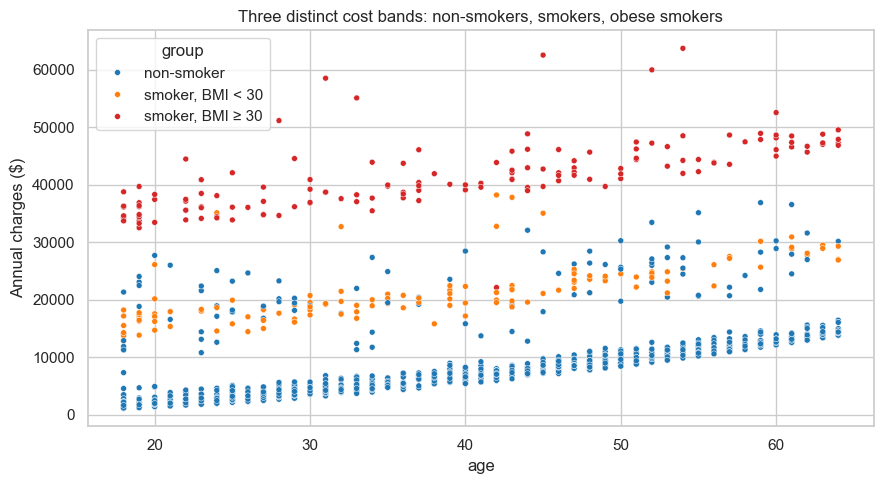

mean  size
smoker obese               
no     0       7977.0   502
       1       8856.0   561
yes    0      21363.0   129
       1      41558.0   145

In [6]:
R["corr"] = {v: {"spearman": stats.spearmanr(d[v], d.charges)[0], "pearson": stats.pearsonr(d[v], d.charges)[0]}
             for v in ["age", "bmi", "children"]}
print(pd.DataFrame(R["corr"]).T.round(3))
d["group"] = np.select([d.smoker.eq("no"), d.obese.eq(0)], ["non-smoker", "smoker, BMI < 30"], "smoker, BMI ≥ 30")
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=d, x="age", y="charges", hue="group", hue_order=["non-smoker", "smoker, BMI < 30", "smoker, BMI ≥ 30"],
                palette=["tab:blue", "tab:orange", "tab:red"], s=18, ax=ax)
ax.set(title="Three distinct cost bands: non-smokers, smokers, obese smokers", ylabel="Annual charges ($)")
fig.tight_layout(); fig.savefig(REPORTS / "cost_bands.png", dpi=120); plt.show()
tab = d.groupby(["smoker", "obese"]).charges.agg(["mean", "size"]).round(0)
R["interaction_means"] = {f"smoker={a}, obese={b}": float(v) for (a, b), v in tab["mean"].items()}
tab

This is the key finding. Costs rise steadily with age in **three parallel bands**. For non-smokers, obesity adds almost
nothing; for smokers it roughly **doubles** the cost. Obesity and smoking **interact** — a model that treats them as
separate, additive factors will mis-state both.

## RQ5 — Modelling costs, with assumption checks

In [7]:
formulas = {
    "A: log(charges), main effects": "log_charges ~ age + bmi + children + C(sex) + C(smoker) + C(region)",
    "B: charges, main effects": "charges ~ age + bmi + children + C(sex) + C(smoker) + C(region)",
    "C: charges, smoker × obese interaction": "charges ~ age + children + C(sex) + C(region) + C(smoker) * obese",
}
kf = KFold(5, shuffle=True, random_state=42)
rows = []
for name, fml in formulas.items():
    fit = smf.ols(fml, d).fit()
    errs = []
    for tr, te in kf.split(d):
        m_ = smf.ols(fml, d.iloc[tr]).fit()
        pred = m_.predict(d.iloc[te])
        pred = np.exp(pred) * np.mean(np.exp(m_.resid)) if fml.startswith("log") else pred   # smearing back-transform
        errs.append(np.sqrt(np.mean((d.charges.iloc[te] - pred) ** 2)))
    rows.append({"model": name, "adj. R² (own scale)": fit.rsquared_adj, "CV RMSE ($)": np.mean(errs)})
comp = pd.DataFrame(rows); R["model_comparison"] = comp.round(3).to_dict("records")
comp.round(3)

,model,adj. R² (own scale),CV RMSE ($)
0,"A: log(charges), main effects",0.766,9580.420
1,"B: charges, main effects",0.749,6105.194
2,"C: charges, smoker × obese interaction",0.862,4498.053


Comparing models on the **same scale** (cross-validated error in dollars) matters: the log model has a decent R² on the log
scale but predicts dollars worse. The interaction model (C) is clearly best — it captures the real structure.

In [8]:
final = smf.ols(formulas["C: charges, smoker × obese interaction"], d).fit(cov_type="HC3")
coef = pd.DataFrame({"coefficient ($)": final.params, "95% CI low": final.conf_int()[0],
                     "95% CI high": final.conf_int()[1], "p-value": final.pvalues})
R["final_coefficients"] = coef.round(3).to_dict("index")
coef.round(1)

,coefficient ($),95% CI low,95% CI high,p-value
Intercept,-1952.8,-2914.0,-991.6,0.0
C(sex)[T.male],-478.6,-968.3,11.1,0.1
C(region)[T.northwest],-276.2,-1015.6,463.2,0.5
C(region)[T.southeast],-587.5,-1294.2,119.1,0.1
C(region)[T.southwest],-1160.8,-1855.2,-466.4,0.0
C(smoker)[T.yes],13360.1,12593.1,14127.0,0.0
age,265.4,248.0,282.8,0.0
children,523.5,334.7,712.4,0.0
obese,203.8,-364.0,771.5,0.5
C(smoker)[T.yes]:obese,19854.8,18726.8,20982.7,0.0


## Assumption checks for the final model

Breusch-Pagan p = 0.888 (a small p would indicate heteroskedastic errors)
VIF: {'C(sex)[T.male]': np.float64(1.01), 'C(region)[T.northwest]': np.float64(1.52), 'C(region)[T.southeast]': np.float64(1.59), 'C(region)[T.southwest]': np.float64(1.53), 'C(smoker)[T.yes]': np.float64(2.13), 'age': np.float64(1.01), 'children': np.float64(1.0), 'obese': np.float64(1.3), 'C(smoker)[T.yes]:obese': np.float64(2.39)}
Observations with Cook's distance > 4/n: 90


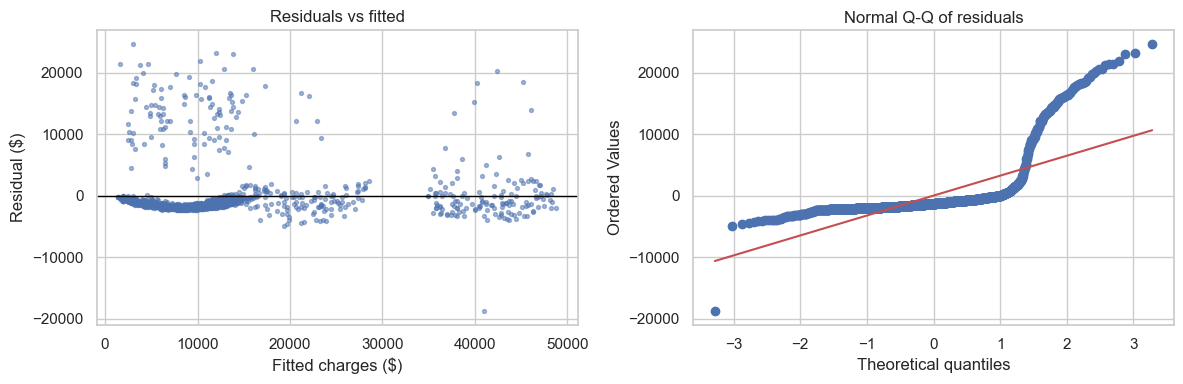

In [9]:
ols_plain = smf.ols(formulas["C: charges, smoker × obese interaction"], d).fit()
bp_stat, bp_p, _, _ = het_breuschpagan(ols_plain.resid, ols_plain.model.exog)
Xv = ols_plain.model.exog; names = ols_plain.model.exog_names
vif = {names[i]: variance_inflation_factor(Xv, i) for i in range(1, Xv.shape[1])}
cooks = ols_plain.get_influence().cooks_distance[0]
R["diagnostics"] = {"breusch_pagan_p": bp_p, "max_vif_excl_interaction": max(v for k, v in vif.items() if ":" not in k and "obese" not in k),
                    "influential_points_4_over_n": int((cooks > 4 / len(d)).sum())}
print(f"Breusch-Pagan p = {bp_p:.3f} (a small p would indicate heteroskedastic errors)")
print("VIF:", {k: round(v, 2) for k, v in vif.items()})
print(f"Observations with Cook's distance > 4/n: {(cooks > 4/len(d)).sum()}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(ols_plain.fittedvalues, ols_plain.resid, s=8, alpha=0.5); ax[0].axhline(0, color="black", lw=1)
ax[0].set(xlabel="Fitted charges ($)", ylabel="Residual ($)", title="Residuals vs fitted")
stats.probplot(ols_plain.resid, dist="norm", plot=ax[1]); ax[1].set(title="Normal Q-Q of residuals")
fig.tight_layout(); fig.savefig(REPORTS / "diagnostics.png", dpi=120); plt.show()

- **Heteroskedasticity**: no evidence of it (Breusch-Pagan p ≈ 0.89); the coefficient table still uses **HC3 robust
  standard errors** as a conservative default.
- **Multicollinearity**: VIFs of the main predictors are low (the interaction term naturally correlates with its components).
- **Residuals**: a cluster of large positive residuals remains — a group of people with much higher charges than the model
  predicts, likely driven by health conditions this dataset does not record. With n > 1,300 the coefficient estimates are
  still reliable (central limit theorem), but individual predictions for these people will be too low.
- **Influence**: the points above Cook's 4/n rule of thumb are almost all this high-cost group; the largest Cook's
  distance is far below 1, and refitting without them barely moves the key interaction coefficient (next cell).

In [10]:
flag = cooks > 4 / len(d)
refit = smf.ols(formulas["C: charges, smoker × obese interaction"], d[~flag]).fit()
key = "C(smoker)[T.yes]:obese"
R["diagnostics"].update({"flagged_with_large_positive_residual": int((flag & (ols_plain.resid > 2 * ols_plain.resid.std())).sum()),
                         "max_cooks_distance": float(cooks.max()), "interaction_without_flagged": float(refit.params[key])})
print(f"{flag.sum()} flagged, {R['diagnostics']['flagged_with_large_positive_residual']} of them with residual > 2 SD; max Cook's distance {cooks.max():.3f}")
print(f"Smoker x obese coefficient: ${ols_plain.params[key]:,.0f} with all data vs ${refit.params[key]:,.0f} without the flagged points")

90 flagged, 89 of them with residual > 2 SD; max Cook's distance 0.022
Smoker x obese coefficient: $19,855 with all data vs $20,066 without the flagged points


In [11]:
(REPORTS / "results.json").write_text(json.dumps(R, indent=2, default=float))

3682

## Conclusions

1. **Smoking is the dominant driver**: smokers pay about 4× more (Cohen's d > 3).
2. **Smoking and obesity interact**: obesity adds almost nothing for non-smokers but roughly **$20,000 a year** for smokers.
3. **Age** adds about **$265 per year**, and each **child** about **$520**, for everyone.
4. **Sex is not an independent driver**: the raw gap in means reflects men smoking more; controlling for smoking it disappears (−$479, p ≈ 0.06).
5. **Region** matters little: no raw difference; with everything else held constant, the southwest is about **$1,200 cheaper**.
6. The interaction model explains **~86%** of the variance in costs and predicts dollars best; remaining large errors point
   to health information the dataset does not contain.

**Implication for an insurer or employer wellness programme:** smoking cessation — especially for smokers with obesity — is
where most of the cost is.